
🔍 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 no

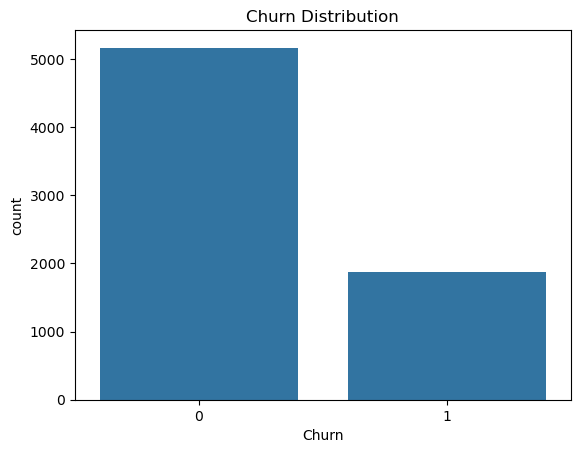

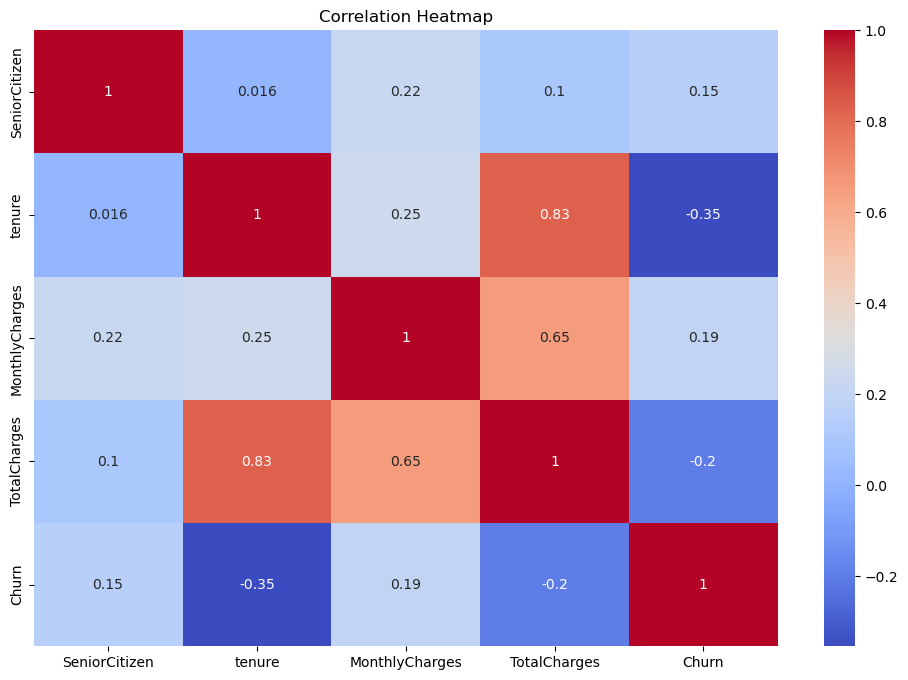


✅ Model Accuracy: 0.79

📄 Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.63      0.48      0.54       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.77      0.79      0.78      1407



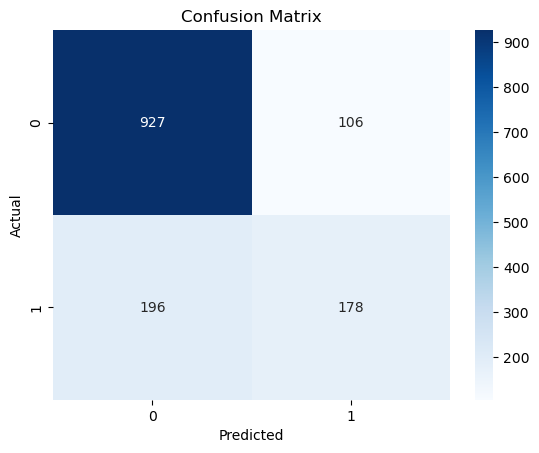

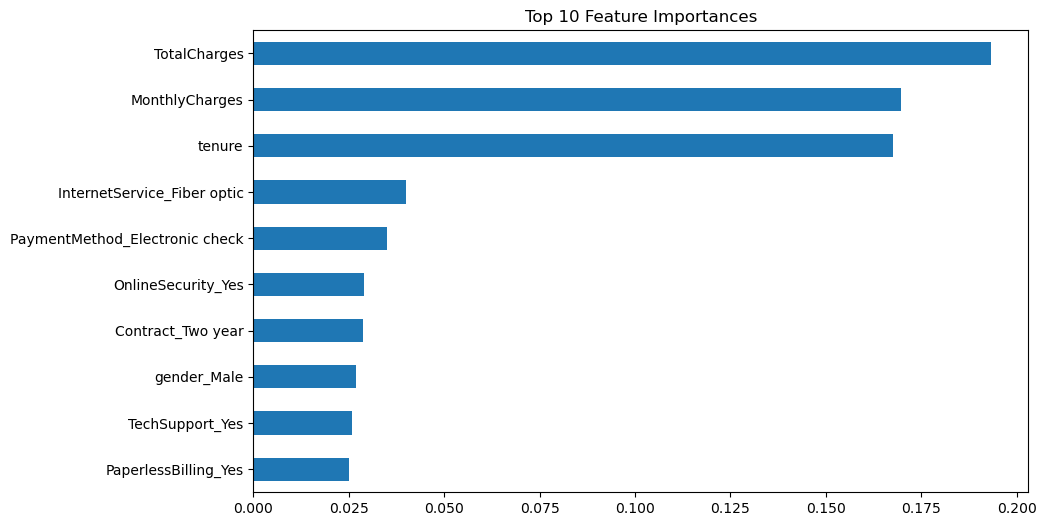


🔚 Case Study Summary:
✔️ Dataset: Telco Customer Churn
✔️ Model Used: Random Forest Classifier
✔️ Accuracy Achieved: 0.79
✔️ Key Features: Tenure, MonthlyCharges, Contract Type, InternetService


In [5]:
#-----> PROJECT 2 Data Science case study
# Customer Churn Prediction - Full Case Study Script
# 1. Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 2. Load dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

# 3. Basic info
print("\n🔍 Dataset Info:")
print(df.info())
print("\n🧾 First 5 Rows:")
print(df.head())

# 4. Clean data
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.dropna(inplace=True)

# Drop customerID
df.drop(["customerID"], axis=1, inplace=True)

# Encode target
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# 5. Exploratory Data Analysis
print("\n📊 Churn Value Counts:")
print(df["Churn"].value_counts())

# Plot churn distribution
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

# Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# 6. Encode categorical variables
df_encoded = pd.get_dummies(df, drop_first=True)

# 7. Split features and target
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 8. Train model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 9. Evaluate model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n✅ Model Accuracy: {accuracy:.2f}")
print("\n📄 Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 10. Feature Importances
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh')
plt.title("Top 10 Feature Importances")
plt.gca().invert_yaxis()
plt.show()

# 11. Summary
print("\n🔚 Case Study Summary:")
print("✔️ Dataset: Telco Customer Churn")
print("✔️ Model Used: Random Forest Classifier")
print("✔️ Accuracy Achieved: {:.2f}".format(accuracy))
print("✔️ Key Features: Tenure, MonthlyCharges, Contract Type, InternetService")
